# API 1: Indexing

cuda


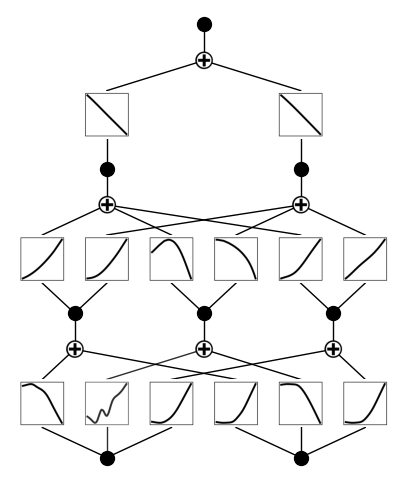

In [1]:
import torch
from xkan import KANNetwork
from xkan.interp import remove_node
from xkan.symbolic import fix_symbolic, unfix_symbolic
from xkan.viz import plot

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

model = KANNetwork([2,3,2,1], noise_scale=0.3, device=device)
x = torch.normal(0,1,size=(100,2)).to(device)
beta = 100
plot(model, x, beta=beta);
# [2,3,2,1] means 2 input nodes
# 3 neurons in the first hidden layer,
# 2 neurons in the second hidden layer,
# 1 output node

### Indexing of edges (activation functions)

Each activation function is indexed by $(l,i,j)$ where $l$ is the layer index, $i$ is the input neuron index, $j$ is the output neuron index. All of them starts from 0. For example, the one in the bottom left corner is (0, 0, 0). Let's try to make it symbolic and see it turns red.

r2 is 0.9962384104728699


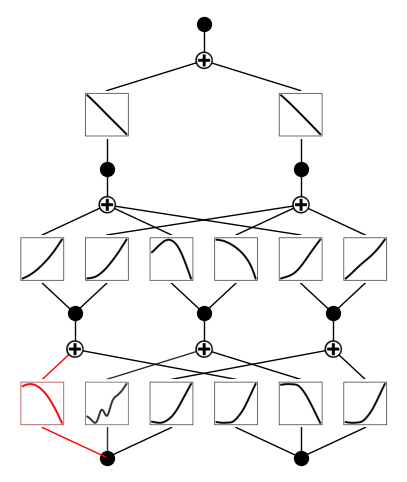

In [2]:
fix_symbolic(model, 0, 0, 0, 'sin', x, verbose=True)
plot(model, x, beta=beta)
unfix_symbolic(model, 0, 0, 0)

r2 is 0.8715552687644958
r2 is not very high, please double check if you are choosing the correct symbolic function.


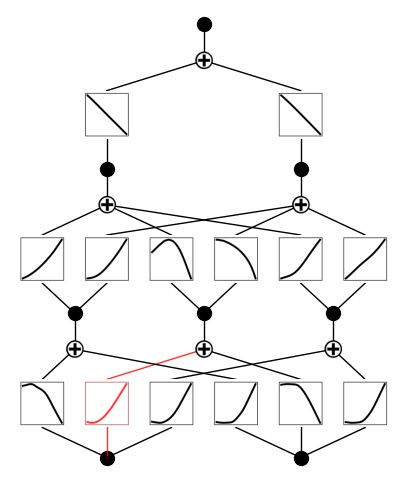

In [3]:
fix_symbolic(model, 0, 0, 1, 'sin', x, verbose=True)
plot(model, x, beta=beta)
unfix_symbolic(model, 0, 0, 1)

r2 is 0.9957033395767212


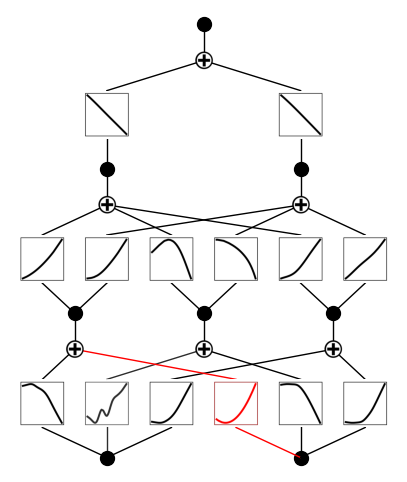

In [4]:
fix_symbolic(model, 0, 1, 0, 'sin', x, verbose=True)
plot(model, x, beta=beta)
unfix_symbolic(model, 0, 1, 0)

r2 is 0.9996441006660461


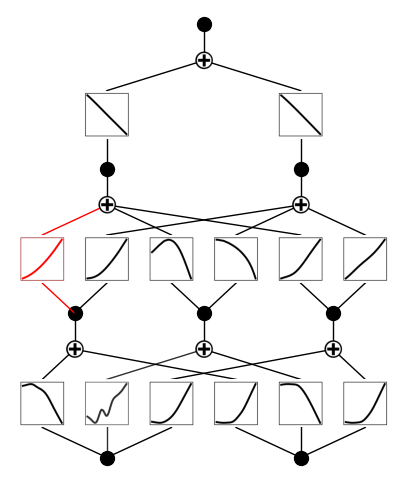

In [5]:
fix_symbolic(model, 1, 0, 0, 'sin', x, verbose=True)
plot(model, x, beta=beta)
unfix_symbolic(model, 1, 0, 0)

r2 is 0.9998388290405273


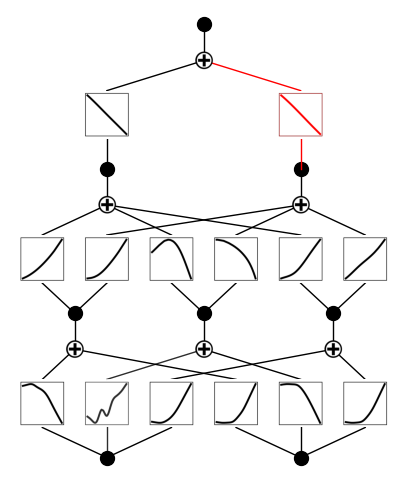

In [6]:
fix_symbolic(model, 2, 1, 0, 'sin', x, verbose=True)
plot(model, x, beta=beta)
unfix_symbolic(model, 2, 1, 0)

### Indexing of nodes (neurons)

Each neuron (node) is indexed by $(l,i)$ where $l$ is the layer index along depth, $i$ is the neuron index along width. In the function remove_node, we use use $(l,i)$ to indicate which node we want to remove.

In [7]:
remove_node(model, 1, 0)

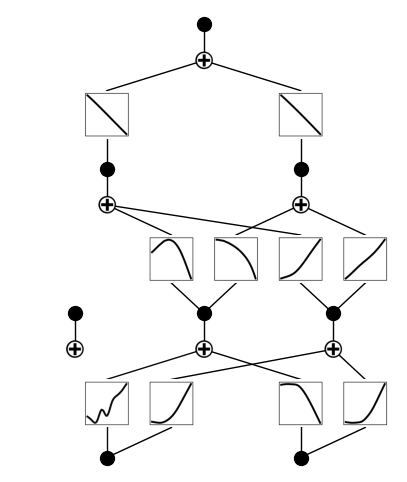

In [8]:
plot(model, x, beta=beta);

In [9]:
remove_node(model, 2, 1)

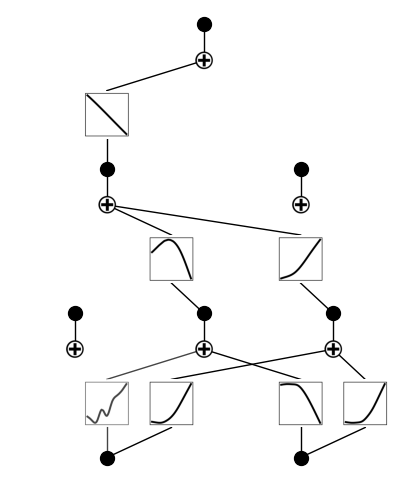

In [10]:
plot(model, x, beta=beta);

In [11]:
remove_node(model, 1, 2)

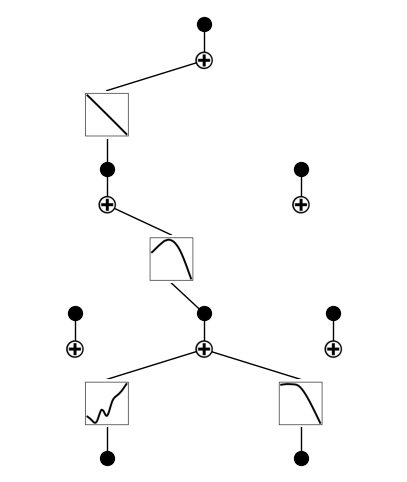

In [12]:
plot(model, x, beta=beta);

### Indexing of layers

In [13]:
# KAN spline layers are model.layers
# KAN symbolic layers are model.symbolic

model = KANNetwork([2,3,5,1])

i = 0
model.layers[i] # => KAN Layer (Spline)
model.symbolic[i] # => KAN Layer (Symbolic)

for i in range(3):
    print(model.layers[i].in_dim, model.layers[i].out_dim)
    print(model.symbolic[i].in_dim, model.symbolic[i].out_dim)

2 3
2 3
3 5
3 5
5 1
5 1


In [14]:
# check model parameters
model.layers[i].grid
model.layers[i].coef
model.symbolic[i].names
model.symbolic[i].mask

tensor([[0., 0., 0., 0., 0.]])